# Hollow (ring) images and the Korolev size correction

### What you will learn

1. what a hollow image (a ring with a lit centre) looks like, and why an out-of-focus drop makes one;
2. how the package's hollow test and reject step treat a ring and a filled disc;
3. the Korolev size correction the package applies to a hollow image, and the tables behind it;
4. what is known about how often this happens;
5. how to count the hollow images in your own data;
6. what is on by default.

### What data this uses

None from disk. Every image is **synthetic**, drawn on a 48 x 48 pixel canvas. A synthetic ring is
a drawn annulus, **not** a simulated diffraction pattern, so it shows what the code does with a
ring and says nothing about the true size of a real out-of-focus drop.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page), [12_particle_gallery](12_particle_gallery.ipynb) (What is not a particle: a gallery of optical array probe artifacts), [14_stray_pixels](14_stray_pixels.ipynb) (Stray pixels and images in pieces). **Related:** [07_hollow_particles](07_hollow_particles.ipynb). **Needs:** the enhancements package and `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The next cell checks that the notebook runs from the repository root, where the paths below start.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys

if "examples" not in sys.path:  # shared helper modules (_style.py) sit in examples/
    sys.path.insert(0, "examples")

## 1. What it looks like

An image is a boolean array: `True` where a diode was in shadow. Time (slices) runs along the horizontal axis and
the diodes along the vertical axis, diode 1 at the top. Left: a filled disc, 20 pixels
across. Next: the same outer size with a lit hole of 3, 6, 10 and 14 pixels in the middle. The bar
below each panel is 100 µm, assuming 10 µm per pixel (rescale for your probe).

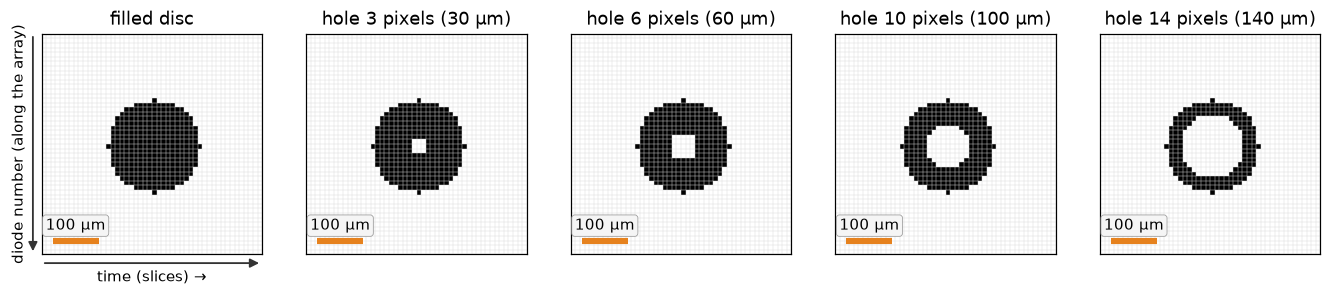

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import _style                  # house style: _style.py sits beside this notebook
_style.apply()

N = 48
ii, jj = np.mgrid[0:N, 0:N]
PX_UM = 10.0   # assumed pixel size (um)

def ring(D, h, c=24):
    r2 = (ii - c) ** 2 + (jj - c) ** 2
    return (r2 <= (D / 2) ** 2) & ((r2 >= (h / 2) ** 2) if h else True)

def show(ax, img, title):
    key = not getattr(ax.figure, "_keyed", False)       # direction key on the first panel of each figure
    ax.figure._keyed = True
    _style.pixels(ax, img, um_per_px=PX_UM, title=title, time_x=True, key=key)

HOLES = [0, 3, 6, 10, 14]
imgs = [ring(20, h) for h in HOLES]
fig, axs = plt.subplots(1, 5, figsize=(15, 3.6))
for ax, im, h in zip(axs, imgs, HOLES):
    show(ax, im, "filled disc" if h == 0 else f"hole {h} pixels ({h * PX_UM:g} µm)")
fig.savefig("examples/figures/hollow_rings.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. Why a drop images as a ring

What the repository's own sources state, from Korolev (2007, *J. Atmos. Oceanic Technol.* 24,
376-389) as summarised in the module docstring of `outoffocus.py`
(`enhancements_uiops/src/arrayprobe_enhancements/`), not re-checked against the paper for this
notebook:

- A sphere away from the probe's focal plane images with a diffraction pattern whose centre is
  lit: the *Poisson spot*. The image is a ring, not a disc.
- It images **larger** than the drop. With $D_0$ the true diameter and $D_{\rm edge}$ the outer
  diameter of the image, $\eta = D_{\rm edge}/D_0 \ge 1$ for every distance $Z_d$ from the focal
  plane (1.0 up to 1.9 in the paper's Fig. 3 and Appendix B table).
- The hole carries the information: the ratio of spot to edge diameter gives $Z_d$, and then
  $D_0 = D_{\rm edge}/\eta(Z_d)$.
- Limits stated there: spherical particles only, and a true diameter of at least 3 pixels.

Other things can leave a lit centre (an ice particle with a hole, for one), and the package's test
cannot tell them apart; it sees only the shadow.

## 3. What the package does with a ring

The hollow test is `arrayprobe_uiops.reject.is_it_hollow` (`arrayprobe_uiops/reject.py:125`). It scans the image
slice by slice and reports whether a lit region is enclosed by shadow, plus the widest hole and
the edge-to-edge span at that hole. `calculate_reject_unified` (`arrayprobe_uiops/reject.py:227`) takes that flag. If the
configuration has `rej_hollow` on and the image is hollow, it forms
$\text{ratio} = D_{\rm hole}/D_{\rm edge}$ and returns one of three codes (`arrayprobe_uiops/reject.py:401-432`):

| Code | Meaning (`matlab_compat.py:709-711`) |
|---|---|
| `'H'` | hollow, Korolev correction applied |
| `'h'` | hollow, no measurable hole ratio |
| `'u'` | hollow, area-to-hole ratio too big (the hole is small against the shadowed area) |

A hole of one pixel or less is not corrected: the particle is accepted as `'0'` at its measured size, with factor 1 (`arrayprobe_uiops/reject.py:420`, `max_hole_diameter <= 1`).

The cell runs both on each image above, with `rej_hollow` on and off, passing the habit `'s'` (a sphere).

In [3]:
from arrayprobe_uiops.min_circle import cgal_min_r_v35
from arrayprobe_uiops.reject import calculate_reject_unified, is_it_hollow
from arrayprobe_uiops.reject_core import RejectConfig

def codes_of(img):
    return np.where(img, 48, 49).astype(np.int64)      # 48 = shadowed, as the engine reads it

def size_px(img):
    return cgal_min_r_v35(codes_of(img), 1.0)[0]       # diameter, pixels (min_circle.py:203)

print(f"{'hole':>5} {'hollow':>6} {'maxhole':>7} {'edge':>5} | {'rej_hollow on':^34} | off")
rows = []
for h, im in zip(HOLES, imgs):
    flag, edge, maxhole = is_it_hollow(im, N)
    on = calculate_reject_unified(codes_of(im), "s", int(flag), RejectConfig(rej_hollow=True))
    off = calculate_reject_unified(codes_of(im), "s", int(flag), RejectConfig(rej_hollow=False))
    rows.append((h, on))
    print(f"{h:>5} {int(flag):>6} {maxhole:>7} {edge:>5} | code {on.reject_status!r:<4} "
          f"Z_d {on.part_z:4.2f} factor {on.size_factor:5.3f} | code {off.reject_status!r}")

 hole hollow maxhole  edge |           rej_hollow on            | off
    0      0       1     1 | code '0'  Z_d -1.00 factor 1.000 | code '0'
    3      1       3    19 | code 'H'  Z_d 1.05 factor 1.278 | code '0'
    6      1       5    19 | code 'H'  Z_d 1.90 factor 1.407 | code '0'
   10      1       9    19 | code 'H'  Z_d 3.80 factor 1.467 | code '0'
   14      1      13    19 | code 'H'  Z_d 6.60 factor 1.861 | code '0'


Reading the table: the filled disc is not hollow and is accepted (`'0'`) either way. Every ring
is found hollow. With `rej_hollow` on, each gets `'H'`, a depth $Z_d$ and a size factor
$\eta$ that grows with the hole. With it off, the same ring is accepted as `'0'` with factor 1:
the hollow block is not run, so the ring would be sized at its outer edge. The hole ratio uses the
*widest* hole row, so one wide row sets the result.

## 4. The Korolev size correction

Both tables are verbatim from `calculate_reject_unified.m` (`arrayprobe_uiops/reject.py:448-486`):
`_SPOT_EDGE` maps the hole ratio to $Z_d$ (`_z_d_lookup`, `arrayprobe_uiops/reject.py:489`) and `_EDGE_0` gives
$\eta = D_{\rm edge}/D_0$ at that $Z_d$ (`_edge_0_lookup`, `arrayprobe_uiops/reject.py:498`). The cell plots them and marks the rings. In the left panel one entry sits far off scale: the table has `0757` where `.757` was meant (the `spot_edge_fix` enhancement below), so the plot is cut at 1.05. The right panel is not monotonic: the factor drops near $Z_d pprox 1.9$ and rises again, as the table is given.

164 table entries; eta runs 1.000 to 1.908


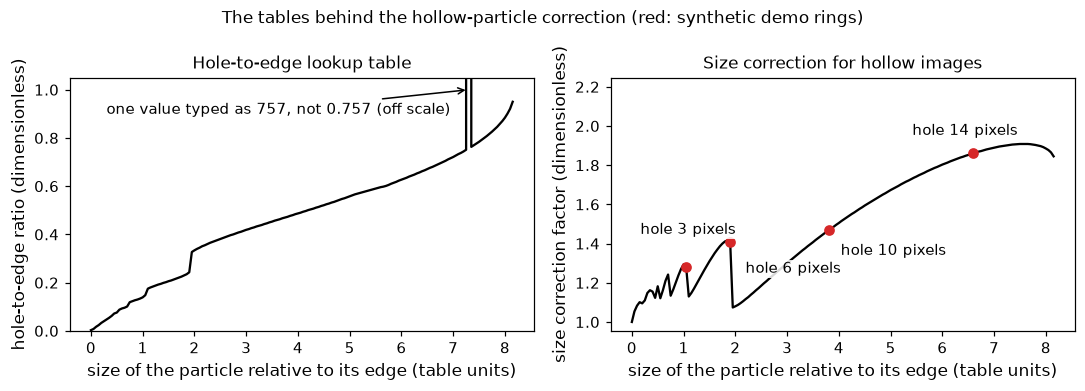

In [4]:
from arrayprobe_uiops import reject as rj

zd = np.array(rj._Z_D)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(zd, rj._SPOT_EDGE, "k-")
axs[0].set_xlabel("size of the particle relative to its edge (table units)")
axs[0].set_ylabel("hole-to-edge ratio (dimensionless)")
spike = int(np.argmax(rj._SPOT_EDGE))
axs[0].set_ylim(0, 1.05)
axs[0].annotate(f"one value typed as {rj._SPOT_EDGE[spike]:g}, not 0.{rj._SPOT_EDGE[spike]:g} (off scale)", (zd[spike], 1.0),
                xytext=(0.3, 0.9), fontsize=10, ha="left", arrowprops={"arrowstyle": "->"})
axs[1].plot(zd, rj._EDGE_0, "k-")
axs[1].set_xlabel("size of the particle relative to its edge (table units)")
axs[1].set_ylabel("size correction factor (dimensionless)")
for h, on in rows:
    if on.reject_status == "H":
        axs[1].plot(on.part_z, on.size_factor, "o", color=_style.FLAG)
        axs[1].annotate(f"hole {h} pixels", (on.part_z, on.size_factor), textcoords="offset points",
                        xytext={3: (-30, 22), 6: (10, -20), 14: (-40, 12)}.get(h, (8, -16)), fontsize=10,
                        bbox={"fc": "white", "ec": "none", "pad": 0.8, "alpha": 0.85})
axs[0].set_title("Hole-to-edge lookup table", fontsize=11)
axs[1].set_title("Size correction for hollow images", fontsize=11)
fig.suptitle("The tables behind the hollow-particle correction (red: synthetic demo rings)", fontsize=11)
plt.tight_layout()
axs[1].set_ylim(top=axs[1].get_ylim()[1] * 1.15)
fig.savefig("examples/figures/hollow_tables.png", dpi=110, bbox_inches="tight")
plt.show()
print(f"{len(zd)} table entries; eta runs {min(rj._EDGE_0):.3f} to {max(rj._EDGE_0):.3f}")

Where the correction is applied:

- **Engine 3.5 (the default engine)** divides: when a particle's reject code is `'H'`,
  `measure_record` sets $D = D/\eta$ (`measure.py:318-320`), and v3.5's own `calculate_reject_unified`
  forces `rej_hollow` on (`measure.py:59-62`). The division is part of stock v3.5
  processing, with no switch. (Read from the source; not re-run through the driver here.)
- **v3.1.4** computes the same factor but never applies it (`outoffocus.py` docstring, upstream
  feedback list). The field-campaign production configuration behind the archived products also turns `rej_hollow` off, so its files carry factor 1.
- The optional `outoffocus` enhancement re-runs the hollow block where it did not run, and
  `correct_diameter` (`outoffocus.py:387`) divides; on a v3.5 run it changes no diameter, only
  `image_area` (`registry.py:726-731`).

Below, `correct_diameter` is applied to the rings' measured sizes. The result is $D_{\rm edge}/\eta$
for a drawn annulus, not a retrieval of a real drop's size.

In [5]:
from arrayprobe_enhancements.outoffocus import correct_diameter

print(f"{'hole':>5} {'measured':>9} {'factor':>7} {'corrected':>10}   (diameters in pixels)")
for h, on in rows:
    d = size_px(ring(20, h))
    fac = on.size_factor
    print(f"{h:>5} {d:9.1f} {fac:7.3f} {float(correct_diameter(d, fac)):10.1f}")

 hole  measured  factor  corrected   (diameters in pixels)
    0      21.0   1.000       21.0
    3      21.0   1.278       16.4
    6      21.0   1.407       14.9
   10      21.0   1.467       14.3
   14      21.0   1.861       11.3


### The measured quantities as a labelled dataset

The ring sizes and factors above, in an `xarray.Dataset` whose variables carry `units`
attributes.

In [6]:
import pandas as pd
import xarray as xr

holes = [h for h, _ in rows]

def var(name, values, units):
    return xr.DataArray(values, dims="hole", coords={"hole": ("hole", holes, {"units": "pixel"})},
                        attrs={"units": units}, name=name)

ds = xr.merge([
    var("measured_size", [size_px(ring(20, h)) for h in holes], "pixel"),
    var("size_factor", [on.size_factor for _, on in rows], "1"),
    var("corrected_size", [float(correct_diameter(size_px(ring(20, h)), on.size_factor))
                           for h, on in rows], "pixel"),
])
ds.attrs["title"] = "Synthetic rings (outer diameter 20 pixels), hollow correction"
ds

<xarray.Dataset> Size: 160B
Dimensions:         (hole: 5)
Coordinates:
  * hole            (hole) int64 40B 0 3 6 10 14
Data variables:
    measured_size   (hole) float64 40B 21.0 21.0 21.0 21.0 21.0
    size_factor     (hole) float64 40B 1.0 1.278 1.407 1.467 1.861
    corrected_size  (hole) float64 40B 21.0 16.43 14.93 14.31 11.28
Attributes:
    units:    pixel
    title:    Synthetic rings (outer diameter 20 pixels), hollow correction

The same numbers as a table, with the units in the column names and the reject code added.

In [7]:
df = ds.to_dataframe()
df.columns = [f"{c} ({ds[c].attrs['units']})" for c in df.columns]
df["reject code"] = [on.reject_status for _, on in rows]
df

,measured_size (pixel),size_factor (1),corrected_size (pixel),reject code
hole,,,,
0,21.0,1.000,21.000000,0
3,21.0,1.278,16.431925,H
6,21.0,1.407,14.925373,H
10,21.0,1.467,14.314928,H
14,21.0,1.861,11.284256,H


The factor grows with the hole, and the corrected size falls below the measured outer size by
that factor.

## 5. How often

- **v3.5's hollow rule**: the `[EXPERIMENTAL]` hollow rule runs unconditionally under
  the shipped default, so it can reject particles a run with the hollow test switched off keeps;
  no rate has been measured on data this package ships.
- **Tiny particles**: the rule makes every particle of two pixels or fewer read hollow
  no rate has been measured.
- **Out-of-focus images**: the fraction of particles that are real hollow images, by size, is
  **not measured yet**. The registry note on the `outoffocus` enhancement puts the particles whose
  area it changes at 0.2-0.4 % (`registry.py:726-731`), which is a different quantity.

## 6. Check your own data

Count how many images in a list the hollow test flags and how many get each hollow code. `images`
is a list of 2-D boolean arrays (`True` = shadow), one per particle; the cell uses this notebook's
images as a stand-in.

In [8]:
images = imgs                              # replace with your own list of 2-D boolean arrays
flags, status = [], []
for im in images:
    f = int(is_it_hollow(im, im.shape[0])[0])
    flags.append(f)
    status.append(calculate_reject_unified(codes_of(im), "s", f, RejectConfig(rej_hollow=True)).reject_status)
print(f"{sum(flags)} of {len(images)} images flagged hollow; "
      f"'H' {status.count('H')}, 'h' {status.count('h')}, 'u' {status.count('u')}")

4 of 5 images flagged hollow; 'H' 4, 'h' 0, 'u' 0


Report the count by size: tiny particles read hollow, and a large particle with an
interior hole may be real.

## 7. Defaults

| | Library | Engine-3.5 batch driver |
|---|---|---|
| Hollow test and `'H'` size division | the function runs when `rej_hollow` is on (default `True`) | on, stock v3.5 (`measure.py:318-320`) |
| `wide_hollow_fix` (the hollow test packs diodes 1-32 only; this widens it) | off (`registry.py:163`) | off for every probe; opt-in by name or `all = true` |
| `outoffocus` (re-runs the hollow block, applies the factor) | off (`registry.py:303`) | off; excluded even from `all = true` on engine 3.5 (`registry.py:736`), opt-in by name |
| `spot_edge_fix` (one table entry is `0757` where `.757` was meant) | off (`registry.py:174`) | off for every probe; opt-in or `all = true` |

None of the three enhancements is in the protective set (`registry.py:763-776`), which holds only the
time-glitch and airspeed-grid fixes. A run's stamp records which were on.

## What to try next

- Draw a ring with a 1-pixel hole and a very small ring and watch which code appears.
- Raise `HOLES` to 18 and see where the factor stops growing.
- Change the habit passed to `calculate_reject_unified` from `'s'` to `'i'` and see the `'u'` code appear for rings with a small hole.
- Next: [17_stuck_diodes.ipynb](17_stuck_diodes.ipynb), stuck diodes and the streaks they draw.